# Приближенный вариационный вывод
Задача: выявить распределение (степень неопределенности обусловнное неучтенными факторами, такими как конкуренты, акции и пр) средних продаж для каждого среза цены

Метод решения:
1. Создаем симуляцию с зараннее заданными параметрами (скрытыми переменными)
2. По результатам симуляции и определеяем эти параметры (скрытыие переменные)
3. Если удастся получить параметры симуляции близкие к заданным, мы можем рассчитывать на то, что в реальных данных определяемые нами скрытые параметры будут также близки к фактическим

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.optim as optim
from scipy.stats import gamma
from torch.distributions import Gamma, Poisson
from scipy.optimize import curve_fit

Симуляция стационарных продаж ($\lambda$ = const для каждого среза цены)

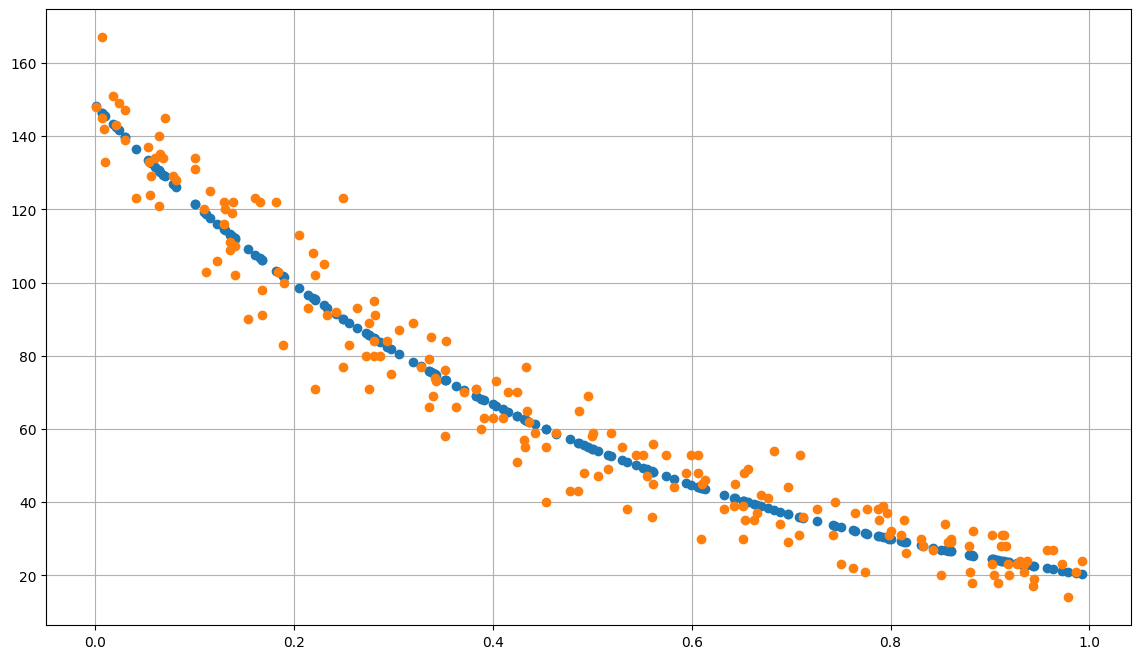

In [ ]:
fig, ax = plt.subplots(figsize=(14, 8))
N = 200
p = np.random.rand(N)
a = -2
b = 5
t = np.exp(a * p + b)
order = np.random.poisson(t)
plt.plot(p, t, "o")
plt.plot(p, order, "o")
plt.grid(True)


Симуляция нестационарных продаж. Теперь $\lambda$ (средние продажи) приходит из Гамма распределения

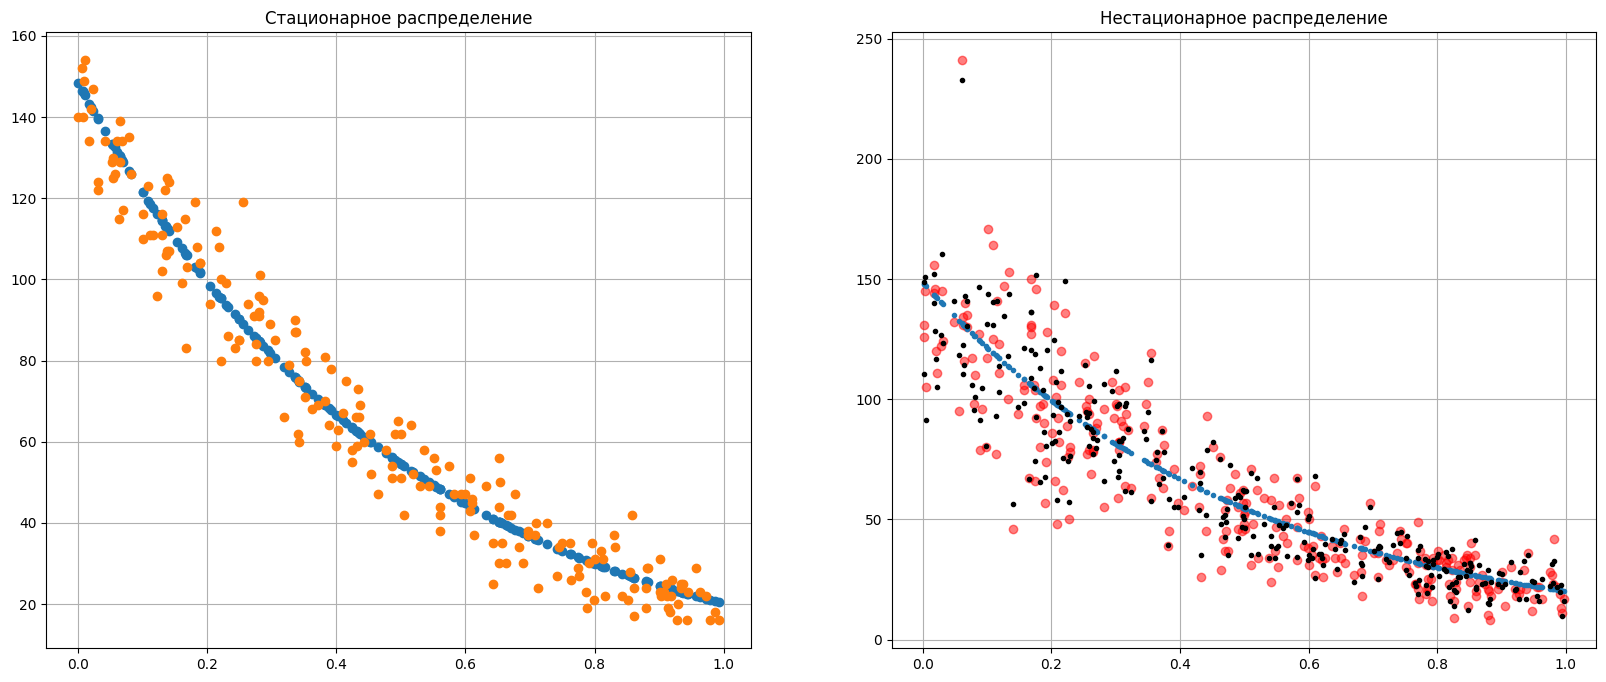

In [ ]:
W0, W1, W2 = 1, 0.5, 0.05


def get_data(a=-2, b=5, w0=W0, w1=W1, w2=W2, N=300):
    """ """
    p = np.random.rand(N)
    E = np.exp(a * p + b)
    D = w0 + E * w1 + E**2 * w2
    shape = E**2 / D
    scale = D / E
    g = np.random.gamma(shape, scale)
    pois = np.random.poisson(g)
    return pois, g, E, p, shape, scale, D


fig, ax = plt.subplots(1, 2, figsize=(20, 8))
t = np.exp(a * p + b)
order = np.random.poisson(t)
ax[0].plot(p, t, "o")
ax[0].plot(p, order, "o")
ax[0].grid(True)
ax[0].set_title("Стационарное распределение")
poes, t, e, p, shape, scale, d = get_data()
# plt.plot(p,t,'.')
# plt.plot(p,e,'.')
ax[1].plot(p, poes, "or", alpha=0.5)
ax[1].plot(p, e, ".")
ax[1].plot(p, t, ".k")
ax[1].set_title("Нестационарное распределение")
ax[1].grid(True);


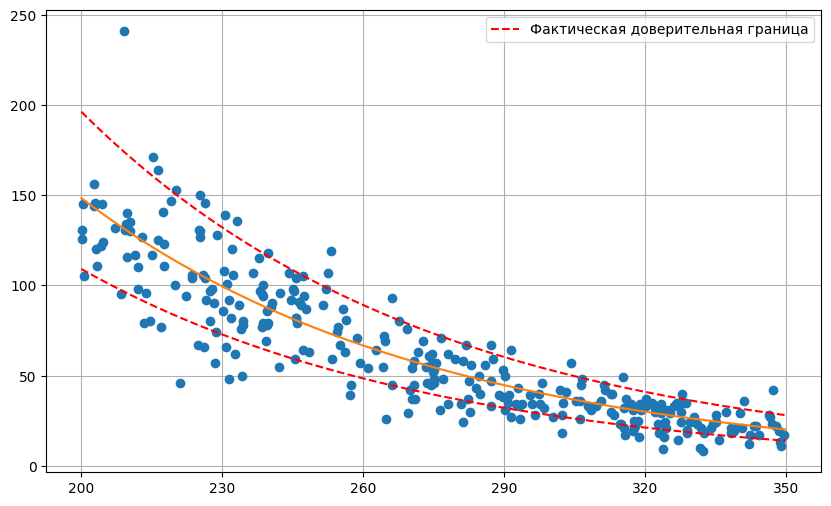

In [ ]:
def get_params(Y, ww0, ww1, ww2):
    t = (ww0 + ww1 * Y + ww2 * Y**2) / Y
    k = Y**2 / (ww0 + ww1 * Y + ww2 * Y**2)
    return t, k


x = np.linspace(0, 1)
Y = np.exp(-2 * x + 5)
t, k =  get_params(Y, W0, W1, W2)
y_up = np.zeros(50)
y_down = np.zeros(50)
y_up_real = np.zeros(50)
y_down_real = np.zeros(50)
for i in range(50):
    #p80 = gamma.ppf([0.1, 0.5, 0.9], a=k, scale=t)
    #f = np.diff(p80)
    #y_up[i] = Y[i] + f[1]
    #y_down[i] = Y[i] - f[0]

    t_real, k_real = get_params(Y[i], W0, W1, W2)
    p80_real = gamma.ppf([0.1, 0.5, 0.9], a=k_real, scale=t_real)
    f_real = np.diff(p80_real)
    y_up_real[i] = Y[i] + f_real[1]
    y_down_real[i] = Y[i] - f_real[0]

plt.figure(figsize=(10, 6))
plt.plot(p, poes, "o")
plt.plot(x, Y)
# plt.plot( x, y_up, "*-k", linewidth=3, label="Доверительная граница полученная в результате оптимизации")
# plt.plot(x, y_down, "*-k", linewidth=3)
plt.plot(x, y_up_real, "--r", label="Фактическая доверительная граница")
plt.plot(x, y_down_real, "--r")
plt.grid(True)
plt.legend()
plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1], [200, 230, 260, 290, 320, 350]);

Пусть спрос $\lambda$ имеет гамма-распределение:

$$p(\lambda\mid k,\theta)=\operatorname{Gamma}(k,\theta),$$

где $k$ — параметр формы, $\theta$ — параметр масштаба.

Математическое ожидание и дисперсия:

$$\mathbb E[\lambda]=k\theta,\qquad \mathbb D[\lambda]=k\theta^2.$$

Отсюда:

$$k=\frac{\mathbb E[\lambda]^2}{\mathbb D[\lambda]},\qquad
\theta=\frac{\mathbb D[\lambda]}{\mathbb E[\lambda]}.$$


Полагая, что $\mathbb E[\lambda]$ оценено экспоненциальной моделью спроса, зададим зависимость дисперсии от среднего:

$$\mathbb D[\lambda]=w_0+w_1\mathbb E[\lambda]+w_2\mathbb E[\lambda]^2.$$

Тогда для каждого наблюдения:

$$k_i=\frac{E_i^2}{w_0+w_1E_i+w_2E_i^2},\qquad
\theta_i=\frac{w_0+w_1E_i+w_2E_i^2}{E_i},$$

где $E_i=\mathbb E[\lambda_i]$. В PyTorch распределение `Gamma` задаётся параметрами `concentration` и `rate`, поэтому при передаче масштаба используется обратная величина.


$$p(k,\theta|o) = \frac{p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)}{\int\int p(o|\lambda)p(\lambda|k,\theta)p(w_0)p(w_1)p(w_2)dw_0 dw_1 dw_2}$$

## ELBO
$$ ELBO = \ln p(o|\lambda) + \ln p(\lambda|k,\theta) + \ln p(w_0)+ \ln p(w_1) + \ln p(w_2) +H[q(w_0)] + H[q[w_1)] + H[q[w_2)]+ H[q(\lambda)]$$
$$ \ln p(\lambda|k,\theta) = \sum_i \ln Gamma(\lambda_i|k_i,\theta_i) $$

In [ ]:
np.random.seed(42)
torch.manual_seed(42)
# get_data(a=-2,b=3,w0=1,w1=0.5,w2 = 0.05,N=300)
poes, t, e, p, shape, scale, d = get_data(a=-2, b=5, N=200)

In [ ]:
def func(price, a, b):
    return np.exp(a * price +b)

popt, pcov = curve_fit(func, p, poes)


E = func(p, popt[0], popt[1])

Для нахождения параметров $w_0$ и $w_1$ применяестя приближенный байесовский вывод. В этом выводе мы оптимизируем нижнюю границу доказательства (Evidence lower bound) [ELBO](https://en.wikipedia.org/wiki/Evidence_lower_bound)

## Задание
1. Найти параметры $ k, \theta$
2. Построить доверительный интервал для оценки матожидания спроса найденный из вариационного вывода и сравнить его с фактическим доверительным интервалом
3. Написать СВОИ выводы

## Решение

Для коэффициентов $w_0,w_1,w_2$ задаются независимые вариационные распределения $q(w_j)=\operatorname{Gamma}(\alpha_j,\beta_j)$, где $\beta_j$ — параметр интенсивности (rate). Берем априорные распределения $p(w_j)=\operatorname{Gamma}(2,1)$.

Наблюдения генерируются по схеме $\lambda_i\sim\operatorname{Gamma}(k_i,\theta_i)$, $o_i\sim\operatorname{Poisson}(\lambda_i)$. После интегрирования скрытой интенсивности $\lambda_i$ получаем маргинальное отрицательное биномиальное распределение для $o_i$. Оптимизируем ELBO методом Монте-Карло.

In [ ]:
# Подготовка данных и оценка среднего спроса E(p)
# Фиксируем seed, чтобы результаты можно было воспроизвести.
np.random.seed(42)
torch.manual_seed(42)

# Данные poes, p уже созданы выше в ноутбуке.
# Оцениваем E(p) = exp(a*p + b) по наблюдаемому спросу.
popt, pcov = curve_fit(func, p, poes, p0=(-2, 5), maxfev=10000)
E_np = func(p, *popt)
E_np = np.maximum(E_np, 1e-6)

print(f"Оценка a = {popt[0]:.4f}, b = {popt[1]:.4f}")
print(f"Среднее оценённое значение спроса: {E_np.mean():.4f}")

Оценка a = -2.0195, b = 5.0121
Среднее оценённое значение спроса: 66.8343


### Оптимизация вариационных параметров

Параметры вариационных апостериорных распределений q(w_j)=Gamma(alpha_j, rate=beta_j):
w0: alpha=1.9918, beta=1.0618, E[w0]=1.8759
w1: alpha=8.2819, beta=7.5330, E[w1]=1.0994
w2: alpha=2.2013, beta=27.5146, E[w2]=0.0800


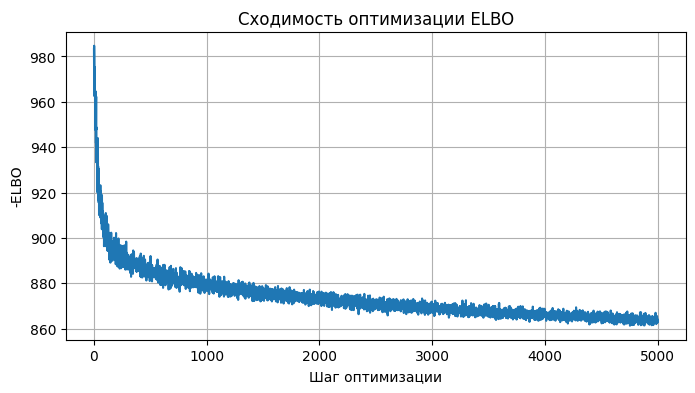

In [ ]:
device = torch.device("cpu")
E_t = torch.tensor(E_np, dtype=torch.float64, device=device)
o_t = torch.tensor(poes, dtype=torch.float64, device=device)

# Неотрицательные параметры Gamma(q): alpha=softplus(raw_alpha), beta=softplus(raw_beta).
raw_alpha = torch.nn.Parameter(torch.zeros(3, dtype=torch.float64))
raw_beta = torch.nn.Parameter(torch.zeros(3, dtype=torch.float64))
optimizer = torch.optim.Adam([raw_alpha, raw_beta], lr=0.02)
prior = Gamma(torch.tensor(2.0, dtype=torch.float64), torch.tensor(1.0, dtype=torch.float64))

n_mc = 128
n_steps = 5000
loss_history = []

for step in range(n_steps):
    optimizer.zero_grad()
    alpha = torch.nn.functional.softplus(raw_alpha) + 1e-4
    beta = torch.nn.functional.softplus(raw_beta) + 1e-4
    q_w = Gamma(alpha, beta)
    w = q_w.rsample((n_mc,))  # [n_mc, 3]
    w0, w1, w2 = w[:, 0:1], w[:, 1:2], w[:, 2:3]

    D = w0 + w1 * E_t.unsqueeze(0) + w2 * E_t.unsqueeze(0).pow(2)
    D = torch.clamp(D, min=1e-8)
    k = E_t.unsqueeze(0).pow(2) / D
    theta = D / E_t.unsqueeze(0)

    # Если lambda~Gamma(k, scale=theta), а o|lambda~Poisson(lambda),
    # то o имеет NegativeBinomial с total_count=k и probs=theta/(1+theta).
    probs = theta / (1.0 + theta)
    likelihood = torch.distributions.NegativeBinomial(total_count=k, probs=probs)
    log_likelihood = likelihood.log_prob(o_t.unsqueeze(0)).sum(dim=1)

    log_prior = prior.log_prob(w).sum(dim=1)
    log_q = q_w.log_prob(w).sum(dim=1)
    elbo = (log_likelihood + log_prior - log_q).mean()
    loss = -elbo
    loss.backward()
    optimizer.step()
    loss_history.append(float(loss.detach()))

alpha_np = (torch.nn.functional.softplus(raw_alpha) + 1e-4).detach().numpy()
beta_np = (torch.nn.functional.softplus(raw_beta) + 1e-4).detach().numpy()

print("Параметры вариационных апостериорных распределений q(w_j)=Gamma(alpha_j, rate=beta_j):")
for j in range(3):
    print(f"w{j}: alpha={alpha_np[j]:.4f}, beta={beta_np[j]:.4f}, "
          f"E[w{j}]={alpha_np[j]/beta_np[j]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Шаг оптимизации")
plt.ylabel("-ELBO")
plt.title("Сходимость оптимизации ELBO")
plt.grid(True)
plt.show()

### 1. Параметры апостериорного распределения спроса

Для каждого значения цены используем найденные вариационные распределения коэффициентов. Средние оценки коэффициентов равны $\mathbb E_q[w_j]=\alpha_j/\beta_j$. Подставляя их в формулы модели, получаем параметры гамма-распределения спроса $k_i$ и $\theta_i$. Дополнительно ниже строится интервал с учётом неопределённости самих коэффициентов.

In [ ]:
# Точечные оценки коэффициентов и параметров Gamma для каждого значения цены.
w_mean = alpha_np / beta_np
D_mean = w_mean[0] + w_mean[1] * E_np + w_mean[2] * E_np**2
k_mean = E_np**2 / D_mean
theta_mean = D_mean / E_np

print("Средние оценки коэффициентов:", w_mean)
print("Первые 5 пар параметров (k, theta):")
for i in range(min(5, len(E_np))):
    print(f"i={i}: k={k_mean[i]:.5f}, theta={theta_mean[i]:.5f}")

Средние оценки коэффициентов: [1.87592875 1.09941283 0.08000466]
Первые 5 пар параметров (k, theta):
i=0: k=10.41950, theta=6.76726
i=1: k=7.47463, theta=2.94676
i=2: k=8.79543, theta=3.89496
i=3: k=9.48279, theta=4.72894
i=4: k=11.08776, theta=9.88707


### 2. Доверительный (апостериорный) интервал и сравнение с фактическим

Строим 90%-й интервал по квантилям 0.05 и 0.95. Для вариационного интервала на каждом шаге берём выборку $w_j$ из $q(w_j)$, рассчитываем $k_i,\theta_i$ и генерируем соответствующее значение $\lambda_i$. Фактический интервал рассчитывается по исходным параметрам симуляции $w_0=1,w_1=0.5,w_2=0.05$.

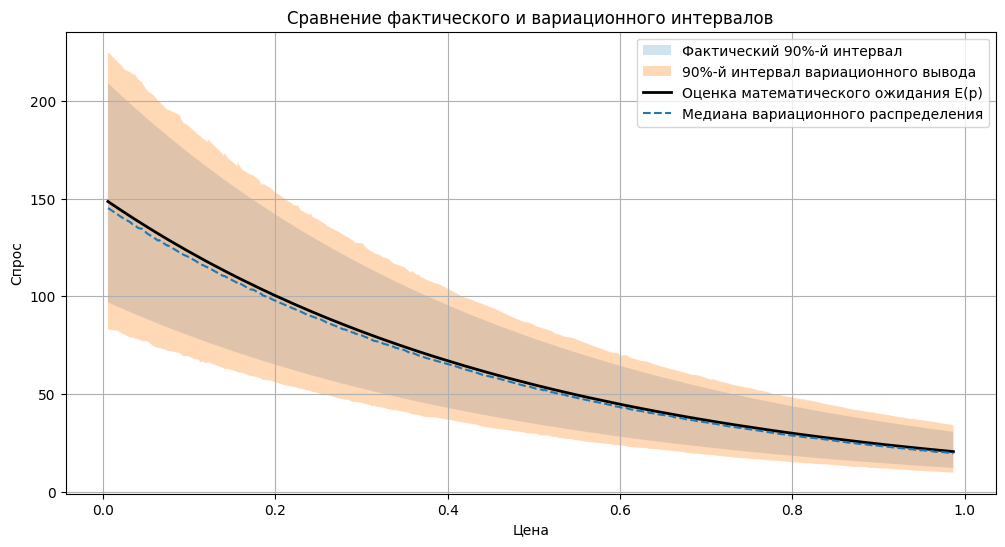

Средняя ширина вариационного интервала: 66.9176
Средняя ширина фактического интервала: 52.4434
Средняя абсолютная ошибка нижней границы: 6.3317
Средняя абсолютная ошибка верхней границы: 8.1424
Доля фактических медиан внутри вариационного интервала: 100.0%


In [ ]:
rng = np.random.default_rng(123)
S = 30000

# Выборки коэффициентов из апостериорных вариационных распределений.
w_samples = np.column_stack([
    rng.gamma(shape=alpha_np[j], scale=1.0 / beta_np[j], size=S)
    for j in range(3)
])

# Апостериорные выборки спроса lambda для каждого наблюдаемого уровня цены.
D_samples = (w_samples[:, 0:1]
             + w_samples[:, 1:2] * E_np[None, :]
             + w_samples[:, 2:3] * E_np[None, :]**2)
D_samples = np.maximum(D_samples, 1e-10)
k_samples = E_np[None, :]**2 / D_samples
theta_samples = D_samples / E_np[None, :]
lambda_samples = rng.gamma(shape=k_samples, scale=theta_samples)

lower_vi, median_vi, upper_vi = np.quantile(lambda_samples, [0.05, 0.5, 0.95], axis=0)

# Фактическое распределение из параметров, использованных при генерации данных.
D_real = W0 + W1 * E_np + W2 * E_np**2
k_real = E_np**2 / D_real
theta_real = D_real / E_np
lower_real = gamma.ppf(0.05, a=k_real, scale=theta_real)
median_real = gamma.ppf(0.50, a=k_real, scale=theta_real)
upper_real = gamma.ppf(0.95, a=k_real, scale=theta_real)

# Сортируем точки по цене.
order = np.argsort(p)
p_sorted = p[order]

plt.figure(figsize=(12, 6))
plt.fill_between(p_sorted, lower_real[order], upper_real[order], alpha=0.20,
                 label="Фактический 90%-й интервал")
plt.fill_between(p_sorted, lower_vi[order], upper_vi[order], alpha=0.30,
                 label="90%-й интервал вариационного вывода")
plt.plot(p_sorted, E_np[order], color="black", linewidth=2,
         label="Оценка математического ожидания E(p)")
plt.plot(p_sorted, median_vi[order], "--", label="Медиана вариационного распределения")
plt.xlabel("Цена")
plt.ylabel("Спрос")
plt.title("Сравнение фактического и вариационного интервалов")
plt.grid(True)
plt.legend()
plt.show()

# Численные показатели сравнения.
width_vi = upper_vi - lower_vi
width_real = upper_real - lower_real
print(f"Средняя ширина вариационного интервала: {width_vi.mean():.4f}")
print(f"Средняя ширина фактического интервала: {width_real.mean():.4f}")
print(f"Средняя абсолютная ошибка нижней границы: {np.mean(np.abs(lower_vi-lower_real)):.4f}")
print(f"Средняя абсолютная ошибка верхней границы: {np.mean(np.abs(upper_vi-upper_real)):.4f}")
print(f"Доля фактических медиан внутри вариационного интервала: "
      f"{np.mean((median_real >= lower_vi) & (median_real <= upper_vi)):.1%}")

### Вывод

Интенсивность продаж зависит от цены и описывается гамма-распределением. По наблюдаемым продажам сначала была оценена зависимость спроса от цены, после чего с помощью вариационного вывода были найдены апостериорные распределения скрытых коэффициентов $w_0,w_1,w_2$.

На  основе полученных распределений рассчитываются параметры гамма-распределения спроса и строится апостериорный интервал.

Вариационный и фактический интервалы близки по ширине и положению, что говорит о хорошем приближении.

Вариационный вывод даёт вероятностную оценку спроса и позволяет учитывать неопределённость скрытых факторов, численные оценки интерпретируются как приближённые.